<a href="https://colab.research.google.com/github/jenitchadha/SDS-510/blob/main/Module_3_essentials_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Dataset - phoenix crime stats

For the **essentials level project** for mod 3, I will be answering three questions as given in the assignment:
*   Draw on multiple sources of data and see how it intersects with the crime data.
*   add  one additional data source.
*   produce, at minimum, one scatter plot and one bar chart.
*   maybe explore some regressions.

In [19]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("mariapushkareva/phoenix-crime-data")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'phoenix-crime-data' dataset.
Path to dataset files: /kaggle/input/phoenix-crime-data


In [20]:
import os

print(os.listdir(path))

['crimestat (1).csv']


Now, I will save the csv file as a df and look at what my dataset looks like.

In [21]:
import pandas as pd
import matplotlib.pyplot as plt
from io import StringIO

with open(path + "/crimestat (1).csv", "r") as file:
    lines = file.readlines()

df = pd.read_csv(StringIO("".join(lines[:-1])))

df.head()

/tmp/ipykernel_639/1251543967.py:8: DtypeWarning: Columns (0) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(StringIO("".join(lines[:-1])))


,INC NUMBER,OCCURRED ON,OCCURRED TO,UCR CRIME CATEGORY,100 BLOCK ADDR,ZIP,PREMISE TYPE
0,201600000052855,11/01/2015 00:00,01/09/2016 00:00,MOTOR VEHICLE THEFT,N 43RD AVE & W CACTUS RD,85029.0,SINGLE FAMILY HOUSE
1,201600000594484,11/01/2015 00:00,NaN,RAPE,13XX E ALMERIA RD,85006.0,SINGLE FAMILY HOUSE
2,201500002102327,11/01/2015 00:00,11/01/2015 09:00,LARCENY-THEFT,51XX N 15TH ST,85014.0,APARTMENT
3,201500002101405,11/01/2015 00:00,11/01/2015 05:00,MOTOR VEHICLE THEFT,102XX W MEDLOCK AVE,85307.0,SINGLE FAMILY HOUSE
4,201500002102668,11/01/2015 00:00,11/01/2015 11:50,MOTOR VEHICLE THEFT,69XX W WOOD ST,85043.0,SINGLE FAMILY HOUSE


For this project, I will answer: how does population relate to reported crime counts across Phoenix zip codes?

First, i will get the reported crime records in each ZIP code

In [22]:
crime_by_zip = df.groupby("ZIP").size().reset_index(name="Crime count")

crime_by_zip.head()

,ZIP,Crime count
0,85003.0,1513
1,85004.0,1650
2,85006.0,2661
3,85007.0,2000
4,85008.0,6320


I see that the zip codes is in decimal. Because the second source I choose will not have zip codes in decimals. So it will be better to remove that.

In [23]:
df = df.dropna(subset=["ZIP"])
df["ZIP"] = df["ZIP"].astype(int).astype(str).str.zfill(5)
df["ZIP"].head()

,ZIP
0,85029
1,85006
2,85014
3,85307
4,85043


In [24]:
df["OCCURRED ON"] = pd.to_datetime(df["OCCURRED ON"], errors="coerce")
df["year"] = df["OCCURRED ON"].dt.year
df = df.dropna(subset=["ZIP", "OCCURRED ON"])
df["ZIP"] = df["ZIP"].astype(int).astype(str).str.zfill(5)

In [25]:
d16 = df[df["year"] == 2016]
crime_by_zip = d16.groupby("ZIP").size().reset_index(name="crimes")
crime_by_zip.head()

,ZIP,crimes
0,85003,656
1,85004,822
2,85006,1249
3,85007,964
4,85008,3034


Now, checking for household income data in az. I will be getting that from kaggle.

In [26]:
import kagglehub

# Download latest version
population_path = kagglehub.dataset_download("census/us-population-by-zip-code")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'us-population-by-zip-code' dataset.
Path to dataset files: /kaggle/input/phoenix-crime-data


In [27]:
print(os.listdir(population_path))

['population_by_zip_2010.csv', 'population_by_zip_2000.csv', '.nfs000000000866f0a60000006b']


So, this dataset has population data for 2000 and 2010. I will use the csv file for 2010 population because it is closer to the crime data range 2015-2016.

In [29]:
population = pd.read_csv(
    os.path.join(population_path, "population_by_zip_2010.csv"))

population.head()

,population,minimum_age,maximum_age,gender,zipcode,geo_id
0,50,30.0,34.0,female,61747,8600000US61747
1,5,85.0,NaN,male,64120,8600000US64120
2,1389,30.0,34.0,male,95117,8600000US95117
3,231,60.0,61.0,female,74074,8600000US74074
4,56,0.0,4.0,female,58042,8600000US58042


In [30]:
print(population.columns.tolist())
print(population.shape)

['population', 'minimum_age', 'maximum_age', 'gender', 'zipcode', 'geo_id']
(1622831, 6)


selecting the total population for each zip code.

In [32]:
population_totals = population[
    population["minimum_age"].isna() &
    population["maximum_age"].isna() &
    population["gender"].isna()
][["zipcode", "population"]].copy()

population_totals.head()

,zipcode,population
36,91324,27669
116,72632,4449
127,72739,473
135,27305,1685
178,1843,24425


checking whether all zipcodes appear only once, that is, having unique values.

In [33]:
print("Rows:", len(population_totals))
print("Unique ZIP codes:", population_totals["zipcode"].nunique())

Rows: 33119
Unique ZIP codes: 33119


merging the tables.

In [34]:
crime_by_zip["ZIP"] = (
    crime_by_zip["ZIP"].astype("string")
    .str.replace(r"\.0$", "", regex=True)
    .str.zfill(5))

population_totals["ZIP"] = (
    population_totals["zipcode"].astype("string")
    .str.replace(r"\.0$", "", regex=True)
    .str.zfill(5))

combined = crime_by_zip.merge(
    population_totals[["ZIP", "population"]],
    on="ZIP",
    how="left",
    validate="one_to_one")

combined.head()

,ZIP,crimes,population
0,85003,656,9369.0
1,85004,822,4965.0
2,85006,1249,25742.0
3,85007,964,14040.0
4,85008,3034,56145.0


In [39]:
print("Rows in crime data:", len(df))
print("Total crimes in combined table:", combined["crimes"].sum())

print("Missing population values:", combined["population"].isna().sum())

Rows in crime data: 131357
Total crimes in combined table: 63225
Missing population values: 1


Rows in crime data: 131357

Total crimes in combined table: 63225

Missing population values: 1

In [40]:
##missing data
combined[combined["population"].isna()]

,ZIP,crimes,population
65,85290,1,NaN


ZIP code 85290 has one crime record but no matching population value. It is probably a good idea here to exclude it from our analysis.

In [41]:
analysis = combined.dropna(subset=["population"]).copy()

Creating a scatter plot

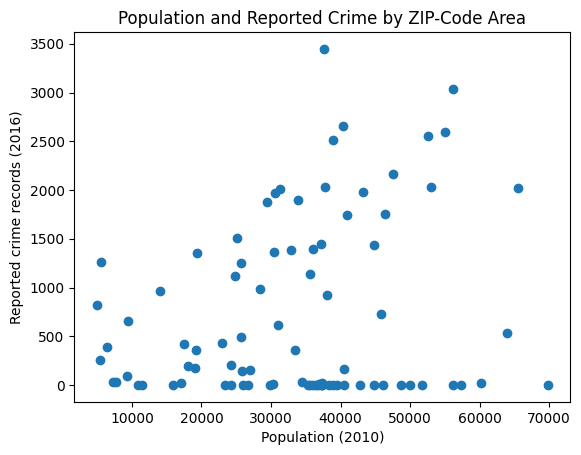

In [43]:
plt.scatter(analysis["population"], analysis["crimes"])

plt.xlabel("Population (2010)")
plt.ylabel("Reported crime records (2016)")
plt.title("Population and Reported Crime by ZIP-Code Area")

plt.show()

The plot shows no clear, consistent relationship between population and reported crime counts. Some larger areas have more records, but many have very few.

Creating a bar chart with 10 areas with the most reported crime records.

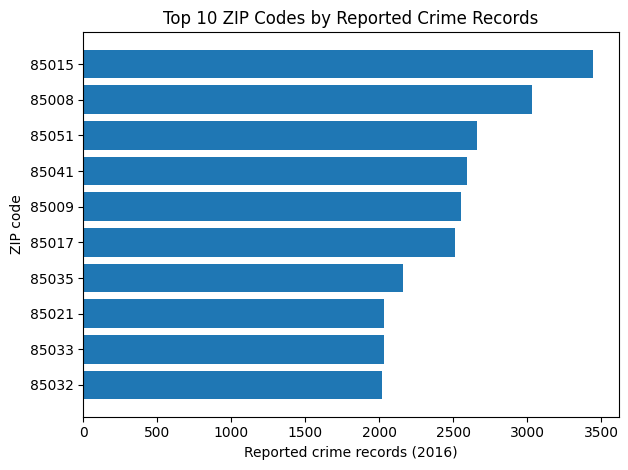

In [44]:
top10 = analysis.nlargest(10, "crimes").sort_values("crimes")

plt.barh(top10["ZIP"].astype(str), top10["crimes"])

plt.xlabel("Reported crime records (2016)")
plt.ylabel("ZIP code")
plt.title("Top 10 ZIP Codes by Reported Crime Records")

plt.tight_layout()
plt.show()

ZIP code 85015 had the most reported crime records in 2016, followed by 85008 and 85051.

saving merged dataset as a csv

In [45]:
analysis.to_csv("Module3_Essentials_Crime_Population.csv", index=False)